This Section will fetch, clean and preprocess the data that is in the database. It filters out cancelled or diverted flights, removes post-departure leakage (DEP_DELAY, DEP_DEL15), and performs a train/test split on months 1 and 2, while using month 3 for testing.

In [1]:
import numpy as np
import pandas as pd
from sqlalchemy import create_engine, text
from sklearn.model_selection import train_test_split

# 1. Connect to SQLite and fetch active flights
engine = create_engine("sqlite:///cap4770_flights.db")

query = text("""
    SELECT 
        MONTH, DAY_OF_MONTH, DAY_OF_WEEK, FL_DATE,
        OP_UNIQUE_CARRIER, ORIGIN, DEST,
        CRS_DEP_TIME, CRS_ARR_TIME, CRS_ELAPSED_TIME, DISTANCE, ARR_DEL15
    FROM bts_flights_raw
    WHERE CANCELLED = 0 
      AND DIVERTED = 0 
      AND ARR_DEL15 IS NOT NULL;
""")

with engine.connect() as conn:
    df_full = pd.read_sql(query, con=conn)

# 2. Clean types before sampling
df_full = df_full.dropna(subset=["CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE"]).copy()
df_full["FL_DATE"] = pd.to_datetime(df_full["FL_DATE"])
df_full["ARR_DEL15"] = df_full["ARR_DEL15"].astype(int)

# 3. Stratified sample of 20,000 flights per month (60,000 total)
SAMPLES_PER_MONTH = 20000
sampled_parts = []

for month, month_df in df_full.groupby("MONTH"):
    if len(month_df) > SAMPLES_PER_MONTH:
        month_sample, _ = train_test_split(
            month_df,
            train_size=SAMPLES_PER_MONTH,
            stratify=month_df["ARR_DEL15"],
            random_state=42
        )
    else:
        month_sample = month_df
    sampled_parts.append(month_sample)

df = pd.concat(sampled_parts, ignore_index=True)

# Free full dataframe from memory
del df_full

# 4. Engineer cyclical time features on the sampled dataset
df["DEP_HOUR"] = (df["CRS_DEP_TIME"] // 100) + ((df["CRS_DEP_TIME"] % 100) / 60.0)
df["ARR_HOUR"] = (df["CRS_ARR_TIME"] // 100) + ((df["CRS_ARR_TIME"] % 100) / 60.0)

df["DEP_SIN"] = np.sin(2 * np.pi * df["DEP_HOUR"] / 24.0)
df["DEP_COS"] = np.cos(2 * np.pi * df["DEP_HOUR"] / 24.0)
df["ARR_SIN"] = np.sin(2 * np.pi * df["ARR_HOUR"] / 24.0)
df["ARR_COS"] = np.cos(2 * np.pi * df["ARR_HOUR"] / 24.0)

print(f"Sampled dataset size: {len(df):,} rows across {df['MONTH'].nunique()} months")
print(df.groupby("MONTH")["ARR_DEL15"].agg(total_flights="count", delay_rate="mean"))

/var/folders/hz/f_xg79k54tq09xsnk84j8_lr0000gn/T/ipykernel_59986/1982357024.py:25: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_full["FL_DATE"] = pd.to_datetime(df_full["FL_DATE"])


Sampled dataset size: 60,000 rows across 3 months
       total_flights  delay_rate
MONTH                           
10             20000     0.19965
11             20000     0.20440
12             20000     0.26885


This section takes the data parsed from the previous cell and creates three plots that each convey a different statistic.
Plot 1 - This line plot measures the arrival delay rate by hour of day.
Plot 2 - This bar plot shows the arrival delay rate by carrier.
Plot 3 - This bar plot shows the arrival plot by day of week.

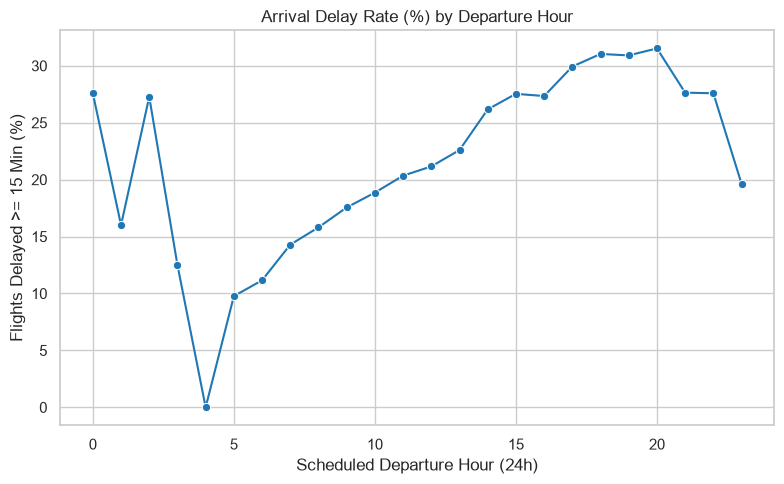

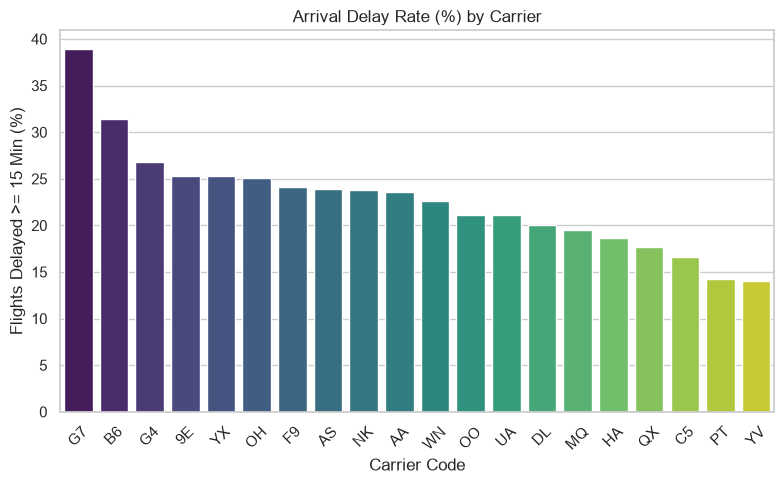

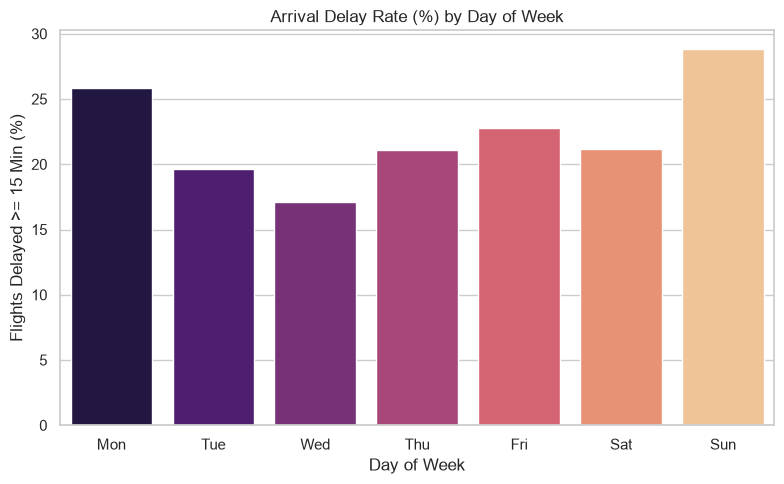

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
# Plot 1: Delay Rate by Scheduled Departure Hour
df["DEP_HOUR_INT"] = (df["CRS_DEP_TIME"] // 100).clip(0, 23)
hourly_delay = df.groupby("DEP_HOUR_INT")["ARR_DEL15"].mean() * 100
fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(x=hourly_delay.index, y=hourly_delay.values, marker="o", ax=ax, color="#1f77b4")
ax.set_title("Arrival Delay Rate (%) by Departure Hour")
ax.set_xlabel("Scheduled Departure Hour (24h)")
ax.set_ylabel("Flights Delayed >= 15 Min (%)")
fig.tight_layout()
fig.savefig("delay_rate_by_departure_hour.png", dpi=300)
plt.show()

# Plot 2: Delay Rate by Airline Carrier
carrier_delay = (
    df.groupby("OP_UNIQUE_CARRIER")["ARR_DEL15"]
    .mean()
    .sort_values(ascending=False) * 100
)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=carrier_delay.index, y=carrier_delay.values, ax=ax, palette="viridis", hue=carrier_delay.index, legend=False)
ax.set_title("Arrival Delay Rate (%) by Carrier")
ax.set_xlabel("Carrier Code")
ax.set_ylabel("Flights Delayed >= 15 Min (%)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig("delay_rate_by_carrier.png", dpi=300)
plt.show()

# Plot 3: Delay Rate by Day of Week
dow_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow_delay = df.groupby("DAY_OF_WEEK")["ARR_DEL15"].mean() * 100
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=dow_labels, y=dow_delay.values, ax=ax, palette="magma", hue=dow_labels, legend=False)
ax.set_title("Arrival Delay Rate (%) by Day of Week")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Flights Delayed >= 15 Min (%)")
fig.tight_layout()
fig.savefig("delay_rate_by_day_of_week.png", dpi=300)
plt.show()

This section trains and compares multiple models to evaluate which model presents the most accurate predicitons.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Chronological Split: Train on first 2 months, test on 3rd month
months = sorted(df["MONTH"].unique())
train_df = df[df["MONTH"].isin(months[:2])]
test_df = df[df["MONTH"] == months[2]]

categorical_cols = ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST"]
numeric_cols = [
    "MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK",
    "CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE",
    "DEP_SIN", "DEP_COS", "ARR_SIN", "ARR_COS"
]

X_train = train_df[categorical_cols + numeric_cols]
y_train = train_df["ARR_DEL15"]
X_test = test_df[categorical_cols + numeric_cols]
y_test = test_df["ARR_DEL15"]

# 2. Preprocessing Transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ]
)

# 3. Define 3 Models (with class balancing for ~20% delay minority class)
models = {
    "Logistic Regression": LogisticRegression(max_iter=500, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=14, class_weight="balanced", n_jobs=-1, random_state=42),
    "Histogram Gradient Boosting": HistGradientBoostingClassifier(max_iter=150, max_depth=8, class_weight="balanced", random_state=42),
}

# 4. Fit & Evaluate
results = []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)
    
    print(f"=== {name} (ROC-AUC: {auc:.4f}) ===")
    print(classification_report(y_test, y_pred, digits=4))

=== Logistic Regression (ROC-AUC: 0.6103) ===
              precision    recall  f1-score   support

           0     0.7905    0.5675    0.6607     14623
           1     0.3345    0.5910    0.4272      5377

    accuracy                         0.5738     20000
   macro avg     0.5625    0.5793    0.5440     20000
weighted avg     0.6679    0.5738    0.5979     20000

=== Random Forest (ROC-AUC: 0.6220) ===
              precision    recall  f1-score   support

           0     0.7943    0.5852    0.6739     14623
           1     0.3426    0.5879    0.4329      5377

    accuracy                         0.5859     20000
   macro avg     0.5684    0.5865    0.5534     20000
weighted avg     0.6729    0.5859    0.6091     20000

=== Histogram Gradient Boosting (ROC-AUC: 0.6155) ===
              precision    recall  f1-score   support

           0     0.7768    0.6832    0.7270     14623
           1     0.3511    0.4662    0.4006      5377

    accuracy                         0.624